In [1]:
# Access to basic math operations like math.sin(), math.pi, math.factorial etc.
import math      

# Core library for scientific computing. Introduces high-performance, multidimensional array objects and fast mathematical operations that operate on entire arrays at once
import numpy as np

# Pyplot module from Matplotlib visualization library. Pyplot provides a state-based interface similar to MATLAB, allowing to create plots, set axes, add labels and format charts with short commands
import matplotlib.pyplot as plt

# This command is specific to Jupyter Notebooks, Googel Colab and similar environments. It forces any graphs generated by Matplotlib to be rendered as static inline images directly below the code cell that created them, rathen than opening in a seperate pop-up window.
%matplotlib inline

In [2]:
# Understanding what is derivative
# Define a function f(x) = 3x^2-4x+5
def f(x):
    return 3*x**2-4*x+5

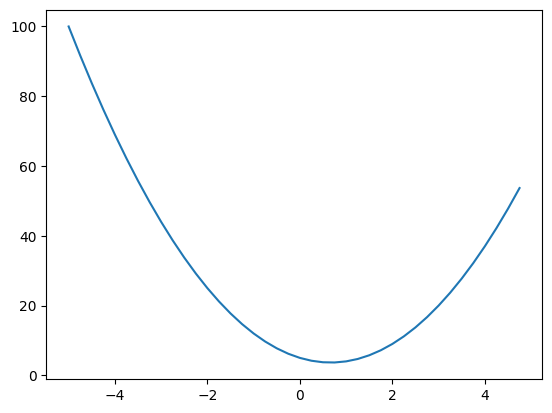

In [3]:
# Take values in an array from -5 to 5 in steps of 0.25 as inputs. Here values 
xs = np.arange(-5, 5, 0.25)

# outputs of the function is taken as ys
ys = f(xs)

# Plot xs vs ys. From pyplot module use the plot function
plt.plot(xs, ys)

In [7]:
# For the function, derivative is (6x)-4. For x = 3, the derivative is therefore 14.
# Let us check this using the defenition of differentiable
h = 0.0001
x = 3
(f(x+h) - f(x))/h

14.000300000063248

In [8]:
# Finding derivatives for a function with three variables
a=2.0
b=-3.0
c=10
d=a*b+c
h=0.0001

# Derviative of d wrt a. By calculus it should be b ie. -3.0
a+=h
da=a*b+c
print(f'a.grad={(da-d)/h}')

# Derviative of d wrt b. By calculus it should be a ie. 2.0
a=2.0
b+=h
db=a*b+c
print(f'b.grad={(db-d)/h}')

# Derviative of d wrt c. By calculus it should be 1 
b=-3.0
c+=h
dc=a*b+c
print(f'a.grad={(dc-d)/h}')

a.grad=-3.000000000010772
b.grad=2.0000000000042206
a.grad=0.9999999999976694


In [4]:
# Defenition of Value object
# Instead of using raw numbers, you will wrap numbers inside this class to give them abilities to keep grad and track _prev nodes.
class Value:

    # The constructor method (__init__). This runs automatically whenever you create a new instance of Value (e.g., x = Value(5)). self refers to the specific instance being created. data is the actual scalar number (like 5.0 or -3.0) passed in as an argument.
    def __init__(self, data):
        # If you run x = Value(5.0), x.data will evaluate to 5.0.
        self.data=data

    # Defines the special string representation method (__repr__ short for representation). This tells Python how to display the object when printed in the console or inspected in a list/Jupyter notebook cell.
    def __repr__(self):
        # Returns a formatted string (f-string) showing the class name and its current data value. Without this method, printing Value(5) would show an ugly memory address like <__main__.Value object at 0x7f9a800>.
        return f"Value(data={self.data})"

    # Overloading of operators
    # Defines Python's dunder (double-underscore) method for addition. When you type a + b, Python automatically translates it under the hood to a.__add__(b)
    def __add__(self, other):
        # Unwraps the underlying raw numbers (self.data and other.data), adds them together, and wraps the resulting sum inside a brand-new Value object named out.
        # By returning a new Value object at every step, these methods allow you to chain operations together while maintaining the Value wrapper throughout the entire chain.
        out = Value(self.data + other.data)
        return out

    def __mul__(self,other):
        out = Value(self.data * other.data)
        return out

In [13]:
# transforms your class from a passive data container into a Directed Acyclic Graph (DAG).
# By tracking which values produced a result and what math operation created it, your engine now remembers its entire execution history.
class Value:

    # _children=(): Accepts a tuple of parent Value objects that were combined to produce this node. Default is an empty tuple () for leaf nodes.
    # label is for indicating name of node in the graph
    def __init__(self, data, _children=(), _op='', label=''):
        self.data=data
        # self._prev = set(_children): Stores those parent nodes in a Python set. A set removes duplicates and provides fast lookup. This forms the backward pointers ("pointers to parents") in your graph.
        self._prev = set(_children)
        # Stores the math symbol ('+') as a string for debugging and graph visualization.
        self._op = _op
        self.label = label
        self.grad = 0.0

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        # (self, other): Passes the two inputs into _children. The new out node now explicitly remembers that it came from self and other.
        # '+': Passes '+' into _op so out knows it was born from an addition operation.
        out = Value(self.data + other.data, (self, other), '+')
        return out

    def __mul__(self,other):
        out = Value(self.data * other.data, (self, other), "*")
        return out

    # Implementing tanh. Requirement for this at cell number [13] below; activation function
    def tanh(self):
        # trick is always to take out the data, do the computation and then wrap it back to value object
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh') #child node is only self. so tuple with self and second value as empty
        return out
        
        

In [2]:
# This is code to implement visualisation of graph
# Not directly in path of study on ML. So using it like an inbuilt module and not explaining this

#Code for Graphical representation of the neural network. WIth Graphviz library

from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name = uid, label = "{%s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            dot.node(name = uid + n._op, label = n._op)
            dot.edge(uid + n._op, uid)
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot
    

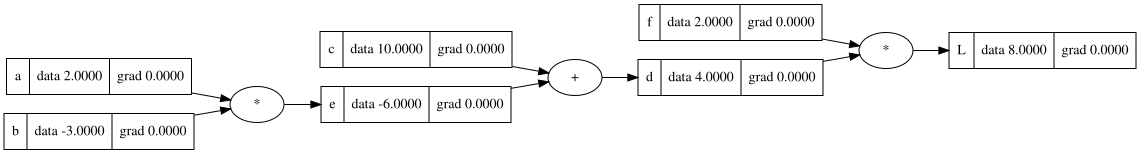

In [7]:
# Use the draw_dot function on last node
a=Value(2.0, label ='a')
b=Value(-3.0, label ='b')
c=Value(10, label ='c')
e = a*b; e.label='e'
d=e+c; d.label='d'
f=Value(2.0, label='f')
L=d*f; L.label='L'
draw_dot(L)

In [11]:
# Filling in grad values manually for all nodes wrt L
# Creating a function called lol() for this

def lol():
# taking value of h
    h = 0.0001
    

# Nudge a by the small value h
    a=Value(2.0+h, label ='a')
    b=Value(-3.0, label ='b')
    c=Value(10, label ='c')
    e = a*b; e.label='e'
    d=e+c; d.label='d'
    f=Value(-2.0, label='f')
    L=d*f; L.label='L'
# Taking the final numerical value of computation
    L2 = L.data


# Nudge b by the small value h
    a=Value(2.0, label ='a')
    b=Value(-3.0+h, label ='b')
    c=Value(10, label ='c')
    e = a*b; e.label='e'
    d=e+c; d.label='d'
    f=Value(-2.0, label='f')
    L=d*f; L.label='L'
# Taking the final numerical value of computation
    L3 = L.data


# Nudge c by the small value h
    a=Value(2.0, label ='a')
    b=Value(-3.0, label ='b')
    c=Value(10+h, label ='c')
    e = a*b; e.label='e'
    d=e+c; d.label='d'
    f=Value(-2.0, label='f')
    L=d*f; L.label='L'
# Taking the final numerical value of computation
    L4 = L.data


# Nudge d by the small value h
    a=Value(2.0, label ='a')
    b=Value(-3.0, label ='b')
    c=Value(10, label ='c')
    e = a*b; e.label='e'
    d=e+c; d.data+=h; d.label='d'
    f=Value(-2.0, label='f')
    L=d*f; L.label='L'
# Taking the final numerical value of computation
    L5 = L.data


# Nudge e by the small value h
    a=Value(2.0, label ='a')
    b=Value(-3.0, label ='b')
    c=Value(10, label ='c')
    e = a*b; e.data+=h; e.label='e'
    d=e+c; d.label='d'
    f=Value(-2.0, label='f')
    L=d*f; L.label='L'
# Taking the final numerical value of computation
    L6 = L.data


# Nudge f by the small value h
    a=Value(2.0, label ='a')
    b=Value(-3.0, label ='b')
    c=Value(10, label ='c')
    e = a*b; e.label='e'
    d=e+c; d.label='d'
    f=Value(-2.0+h, label='f')
    L=d*f; L.label='L'
# Taking the final numerical value of computation
    L7 = L.data

    a=Value(2.0, label ='a')
    b=Value(-3.0, label ='b')
    c=Value(10, label ='c')
    e = a*b; e.label='e'
    d=e+c; d.label='d'
    f=Value(-2.0, label='f')
    L=d*f; L.label='L'
# Taking the final numerical value of computation
    L1 = L.data


    a.grad = (L2-L1)/h
    b.grad = (L3-L1)/h
    c.grad = (L4-L1)/h
    d.grad = (L5-L1)/h
    e.grad = (L6-L1)/h
    f.grad = (L7-L1)/h

    return (a.grad,b.grad,c.grad,d.grad,e.grad,f.grad,1.0)

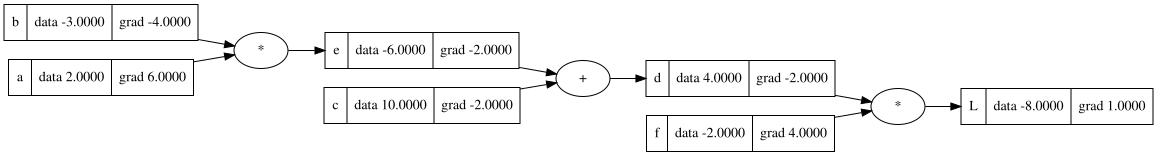

In [12]:
a=Value(2.0, label ='a')
b=Value(-3.0, label ='b')
c=Value(10, label ='c')
e = a*b; e.label='e'
d=e+c; d.label='d'
f=Value(-2.0, label='f')
L=d*f; L.label='L'
a.grad,b.grad,c.grad,d.grad,e.grad,f.grad,L.grad = lol()
draw_dot(L)

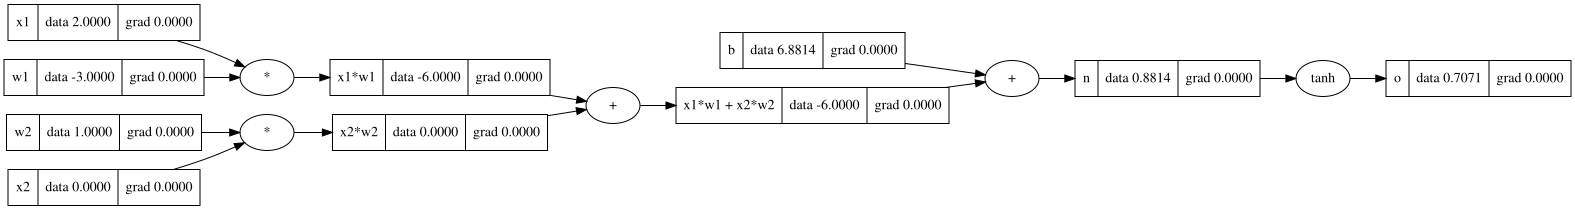

In [5]:
# Neuron has inputs multiplited by weights, added with bias and passed through squasing function
# Implement f(x1*w1 + x2*w2 + b); where f is tanh

# Inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# Weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# Bias b
b = Value(6.8813735870195432, label='b') #if we increase value of bias, tanh will reach the limit value of 1.0. Here andrej suggested this number for bias, to demonstrate clean values that he new previously

# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'

# tanh of the value
o = n.tanh(); o.label = 'o'
draw_dot(o)
           

In [18]:
# Now we do backpropagation to find the gradients
# Manual computation
# o.grad = 1.0
# n.grad = do/dn = 1-(o)**2 = 1-(0.7071)**2 = 0.5
# b.grad = 0.5
# (x1.w1+x2.w2).grad = 0.5
# (x1.w1).grad = 0.5
# (x2.w2).grad = 0.5
# x1.grad = -1.5
# w1.grad = 1.0
# x2.grad = 0.5
# w2.grad = 0.0

In [22]:
# Defining backpropagation for each operation
class Value:

    def __init__(self, data, _children=(), _op='', label=''):
        self.data=data
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self.grad = 0.0
        # adding _backward function for all Value objects and default to None, for leaf node
        self._backward = lambda : None

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        # Checking if it is a value object. Else making it one
        other = other if isinstance (other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        # Defining _backward function. Refer page 7 of written notes
        def _backward():
            self.grad += 1.0 * out.grad    #accumulating grad
            other.grad += 1.0 * out.grad
        out._backward = _backward  # pointer to this defenition of _backward funtion for the current node
        return out

    def __mul__(self,other):
        other = other if isinstance (other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __rmul__(self,other):
        return self*other

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh')
        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def exp(self):
        out.data = Value(math.exp(self.data), (self, ), 'exp')
        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        return out

    def __pow__(self, other):
        assert isinstance (other, (int, float)), "only support int/float for other"
        out = Value(self.data**other, (self, ), f'**other')
        def _backward():
            self.grad += (other*self.data**(other-1))*out.grad
        out._backward=_backward
        return out

    # directly using values with above defined funtions for multiplication and power
    def __truediv__(self, other):
        return self*other**-1

    # subtraction with existing defenitions of multiplication and addition. Using dunder methods __neg__ and __sub__
    def __neg__(self):
        return self*-1

    def __sub__(self, other):
        return self

In [11]:
# base case is o.grad = 1.0. set this
o.grad = 1.0

In [17]:
# calling _backward function for o
o._backward()

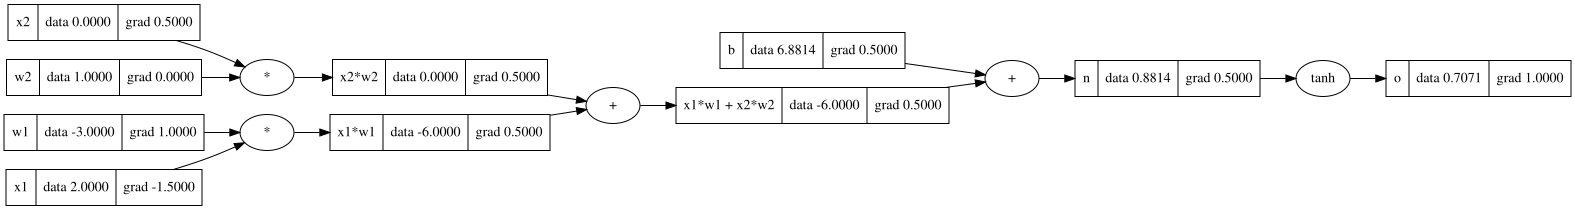

In [18]:
# calling _backward function for each operation
n._backward()
x1w1x2w2._backward()
x2w2._backward()
x1w1._backward()
draw_dot(o)

In [20]:
# building list of nodes in topological order sorted. Only a node is added in list after all its children are added in the list already.
topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)
topo

[Value(data=-3.0),
 Value(data=2.0),
 Value(data=-6.0),
 Value(data=0.0),
 Value(data=1.0),
 Value(data=0.0),
 Value(data=-6.0),
 Value(data=6.881373587019543),
 Value(data=0.8813735870195432),
 Value(data=0.7071067811865476)]

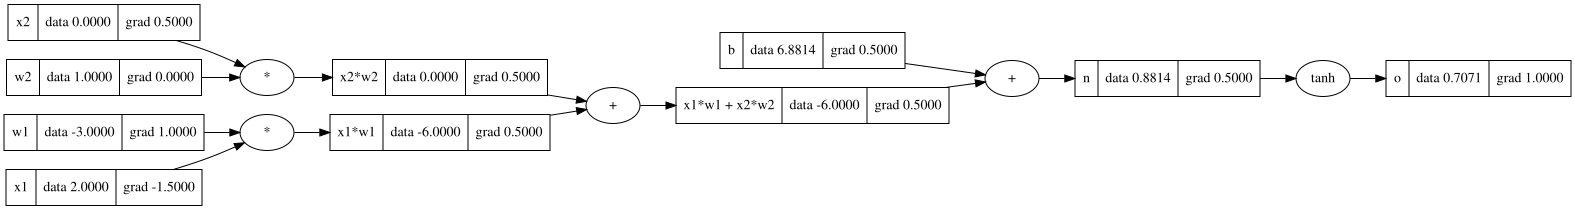

In [21]:
# base case
o.grad = 1.0

# topological ordered list of nodes
topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)

# call _backward() function in reverse order of list of nodes in topological sorrted
for node in reversed(topo):
    node._backward()

draw_dot(o)

In [3]:
# Now adding the functionality for automated call of backward to Value class

class Value:

    def __init__(self, data, _children=(), _op='', label=''):
        self.data=data
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self.grad = 0.0
        # adding _backward function for all Value objects and default to None, for leaf node
        self._backward = lambda : None

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        # Checking if it is a value object. Else making it one
        other = other if isinstance (other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        # Defining _backward function. Refer page 7 of written notes
        def _backward():
            self.grad += 1.0 * out.grad    #accumulating grad
            other.grad += 1.0 * out.grad
        out._backward = _backward  # pointer to this defenition of _backward funtion for the current node
        return out

    def __radd__(self, other):
        return self + other

    def __mul__(self,other):
        other = other if isinstance (other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __rmul__(self,other):
        return self*other

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh')
        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def exp(self):
        out = Value(math.exp(self.data), (self, ), 'exp')
        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        return out

    def __pow__(self, other):
        assert isinstance (other, (int, float)), "only support int/float for other"
        out = Value(self.data**other, (self, ), f'**{other}')
        def _backward():
            self.grad += (other*self.data**(other-1))*out.grad
        out._backward=_backward
        return out

    # directly using values with above defined funtions for multiplication and power
    def __truediv__(self, other):
        return self*(other**-1)

    # subtraction with existing defenitions of multiplication and addition. Using dunder methods __neg__ and __sub__
    def __neg__(self):
        return self*-1

    def __sub__(self, other):
        return self+(-other)
        
# Define a backward (without underscore) function for the value class

    def backward(self):
        # Build topological graph
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        # build topological graph, starting at self node
        build_topo(self)

        # Set self.grad to 1.0
        self.grad = 1.0
    # call _backward() function defined in operations of value class, in reverse order of list of nodes in topological sorrted
        for node in reversed(topo):
            node._backward()

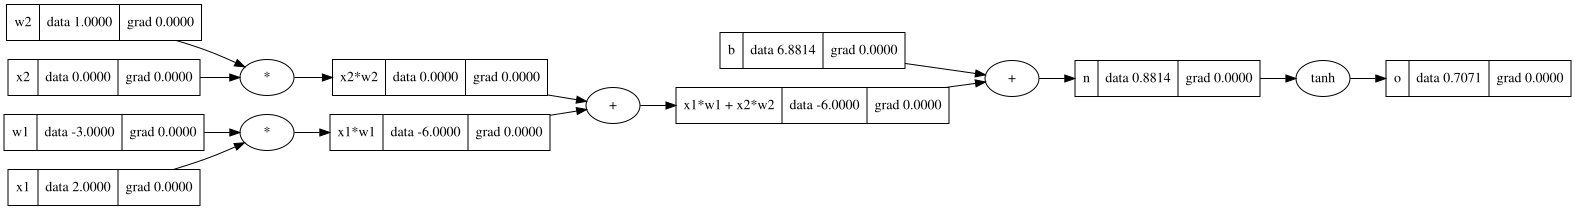

In [16]:
# Reimplementing neuron with grad = 0

# Inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# Weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# Bias b
b = Value(6.8813735870195432, label='b') #if we increase value of bias, tanh will reach the limit value of 1.0. Here andrej suggested this number for bias, to demonstrate clean values that he new previously

# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'

# tanh of the value
o = n.tanh(); o.label = 'o'
draw_dot(o)

In [17]:
# calling the backpropagation function in Value class to determine the gradients
o.backward()

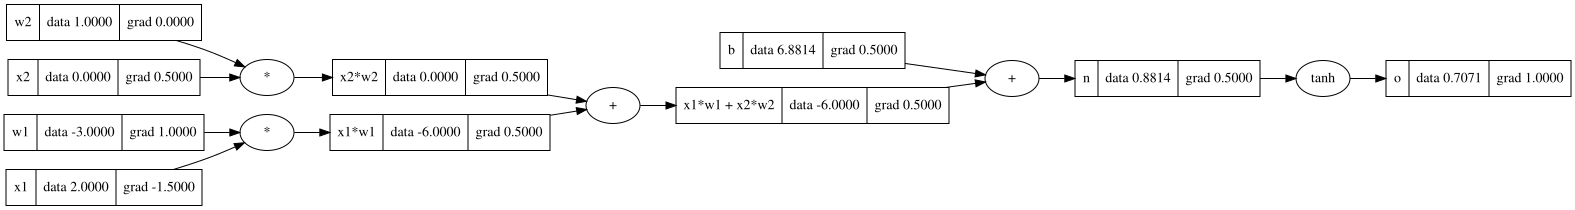

In [18]:
# drawing the graph with gradients
draw_dot(o)

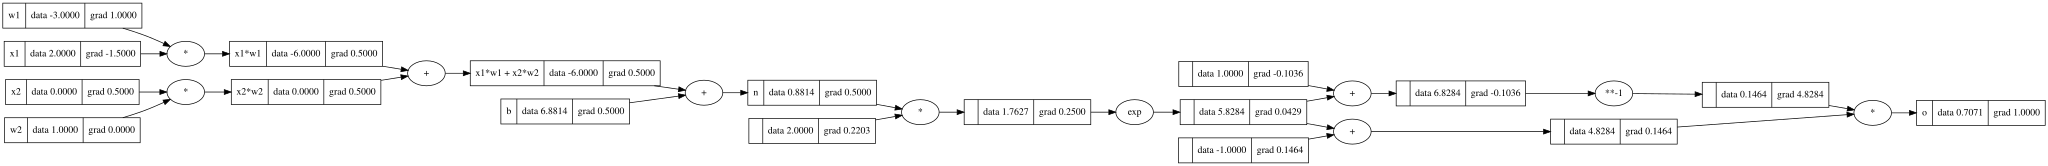

In [32]:
# Now instead of tanh, let us use the exponential composition of tanh ie. (e^2x - 1)/ (e^2x + 1)
# When we substitue for this, we will see a longer expression in place of tanh, in the graph and
# the output data, ie result of forward pass as well as the gradients of input nodes, ie result of backward pass are same

x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

b = Value(6.8813735870195432, label='b') 

x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'

# implementing expression of tanh with __exp__ and __truediv__
e = (2*n).exp()
o = (e-1)/(e+1)
o.label = 'o'
o.backward()
draw_dot(o)

In [35]:
# Using PyTorch library
# Read page 10 of notes to understand this

import torch

x1 = torch.Tensor([2.0]).double(); x1.requires_grad=True
x2 = torch.Tensor([0.0]).double(); x2.requires_grad=True
w1 = torch.Tensor([-3.0]).double(); w1.requires_grad=True
w2 = torch.Tensor([1.0]).double(); w2.requires_grad=True
b = torch.Tensor([6.8813735870195432]).double(); b.requires_grad=True

#forward pass
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)
print(o.data.item())
print('-----')

#backward pass
o.backward()
print('x1', x1.grad.item())
print('x2', x2.grad.item())
print('w1', w1.grad.item())
print('w2', w2.grad.item())


# Everything we implemented in micrograd is simply available for granted in PyTorch :)

0.7071066904050358
-----
x1 -1.5000003851533106
x2 0.5000001283844369
w1 1.0000002567688737
w2 0.0


In [15]:
# Refer page 11 of notes
# Implementing Neuron

import torch
import random

class Neuron:

    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self,x):
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

x = [2.0, 3.0]
n = Neuron(2)   # This calls __init__()
n(x)            # This calls __call__()

Value(data=0.9848925242859002)

In [18]:
# Refer page 12 of notes
# Implementing Layer of Neurons

class Layer:

    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self,x):
        outs = [n(x) for n in self.neurons]
        return outs

x = [2.0, 3.0]    # Inputs
n = Layer(2, 3)   # This calls __init__() with nin = dimensions = weights = 2 and nout = number of outputs = number of neurons in layer = 3
n(x)            # This calls __call__()

[Value(data=-0.2534940212721905),
 Value(data=0.9980449569325498),
 Value(data=-0.2231373219343597)]

In [22]:
# Refer page 13 of notes
# Implementing MLP

class MLP:

    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

n = MLP(3, [4,4,1])
x = [2.0,3.0,-1.0]
n(x)

[Value(data=-0.5532701979393535)]

In [4]:
# Above, the output is coming as a list from Layer class. For single output, we can print it as a value and not a list
# Putting all three classes together, with this modification, we have forward pass of an MLP

import torch
import random

class Neuron:

    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self,x):
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

class Layer:

    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self,x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs # this is the modification

class MLP:

    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

n = MLP(3, [4,4,1])
x = [2.0,3.0,-1.0]
n(x)
        

Value(data=-0.44826149481002076)

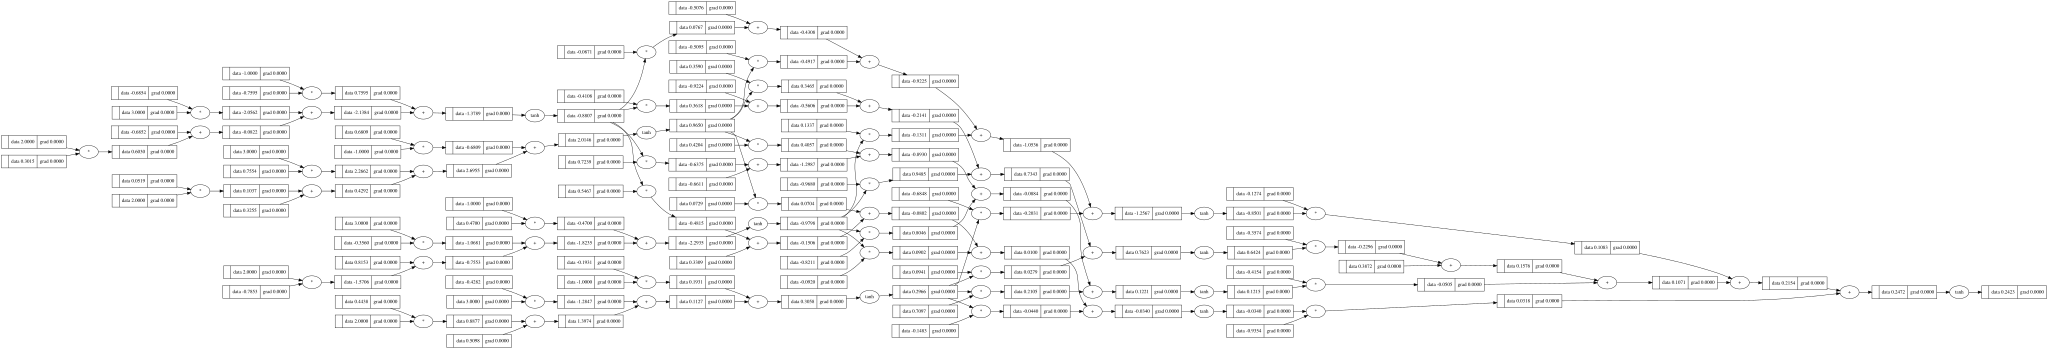

In [28]:
draw_dot(n(x))

In [5]:
# Page 14 of notes
# Binary Classifier Dataset

xs = [
    [2.0, 3.0, -1.0],       #inputs
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]  #desired outputs

# what are the initial predictions by our above MLP for inputs
ypred = [n(x) for x in xs]
ypred

[Value(data=-0.44826149481002076),
 Value(data=0.09519705107416741),
 Value(data=-0.19973364117051645),
 Value(data=-0.33564234253617803)]

In [6]:
# From above results we want a method to make the predictions close to desired outputs, using backpropagation

loss = sum((yout-ygt)**2 for ygt, yout in zip(ys, ypred))
loss

Value(data=5.721284650280637)

In [7]:
loss.backward()

In [8]:
n.layers[0].neurons[0].w[0].grad

0.7961018345426685

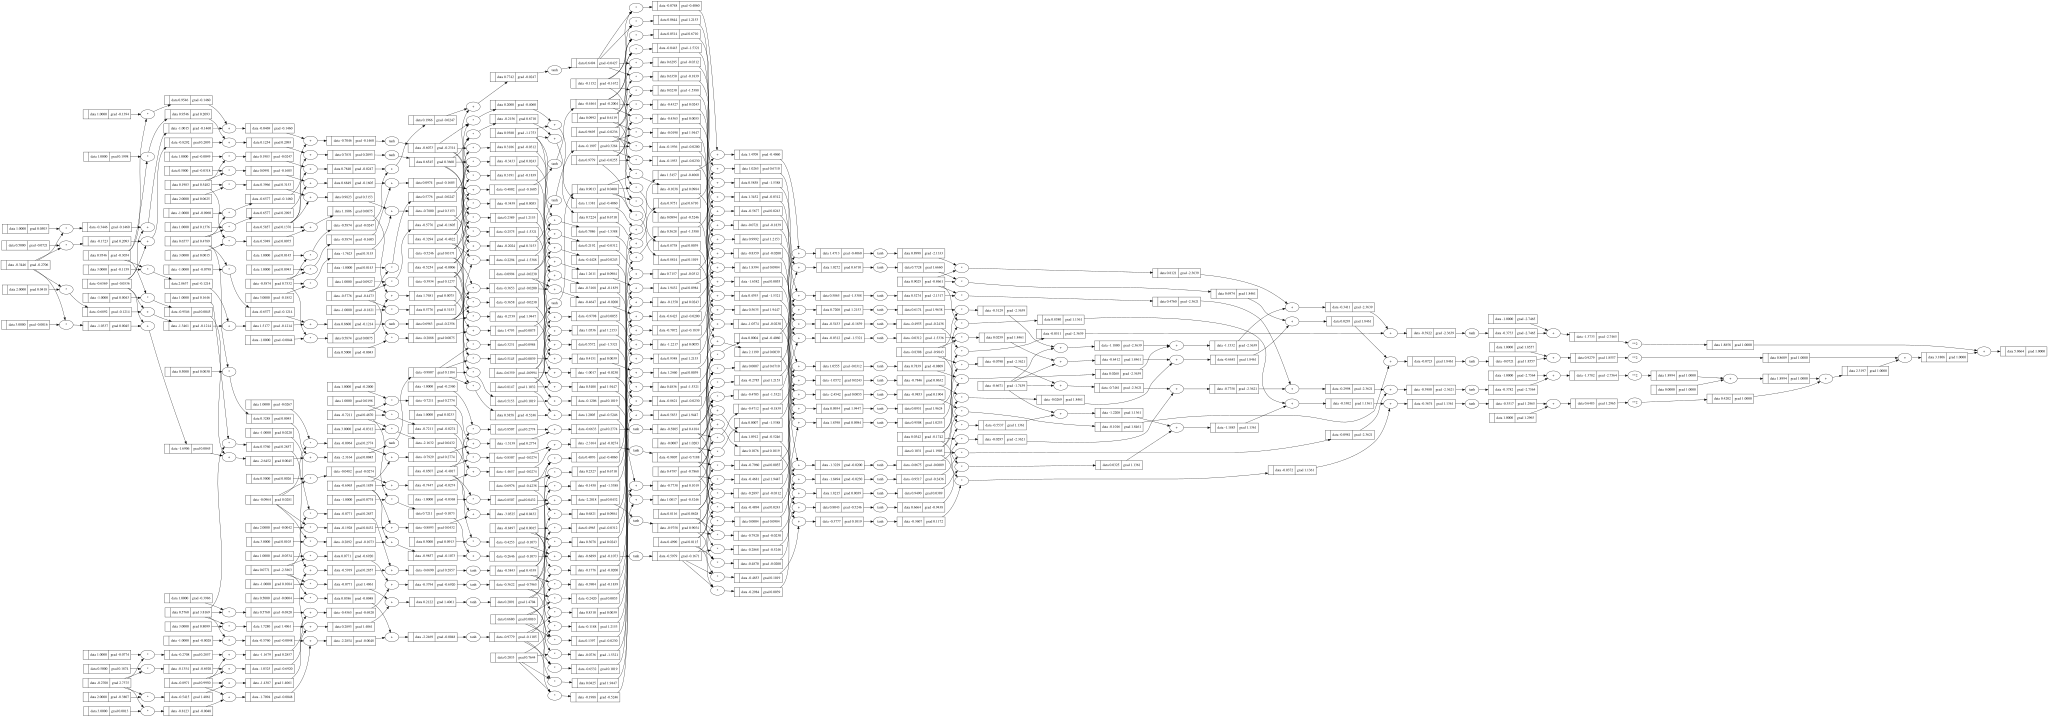

In [9]:
draw_dot(loss)

In [63]:
# Refer page 15 of notes
# Adding function defenition in all three classes, so that MLP can return list of weights and biases of entire network as the network parameters

import torch
import random

class Neuron:

    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self,x):
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:

    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self,x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs 

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]
        
class MLP:

    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [64]:
# reinitialising the network, since we add new functionality for returning parameters

n = MLP(3, [4,4,1])
x = [2.0,3.0,-1.0]
n(x)

Value(data=-0.0317007238686932)

In [11]:
n.parameters()

[Value(data=-0.7315495230528792),
 Value(data=-0.02964530537884147),
 Value(data=0.6451704764268076),
 Value(data=-0.4691842971433864),
 Value(data=-0.4653767041904737),
 Value(data=-0.27957767967903546),
 Value(data=0.980185091612769),
 Value(data=-0.16663116698554226),
 Value(data=-0.7551936834224038),
 Value(data=-0.5947417681911908),
 Value(data=-0.9941066807920946),
 Value(data=-0.1941342453209367),
 Value(data=0.13772659177882818),
 Value(data=-0.6757660927301437),
 Value(data=0.45683418374075635),
 Value(data=-0.3778396342056911),
 Value(data=-0.42277673390671255),
 Value(data=-0.991346076321409),
 Value(data=0.4846867682614615),
 Value(data=0.7107945535748141),
 Value(data=0.6048969105787065),
 Value(data=0.7855988773301485),
 Value(data=0.044221938530537575),
 Value(data=0.8889407100169395),
 Value(data=-0.7878210946004196),
 Value(data=0.8087612346668103),
 Value(data=0.7427498178095824),
 Value(data=0.5868927039448533),
 Value(data=-0.38677784502105905),
 Value(data=-0.25989

In [12]:
# The above are total parameters ie., weights and biases of this MLP

len(n.parameters())

41

In [65]:
# Dataset

xs = [
    [2.0, 3.0, -1.0],       #inputs
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]  #desired outputs

In [22]:
# Forward Pass
# predictions by our above MLP for inputs
ypred = [n(x) for x in xs]

In [15]:
#Calculate Initial Loss. Dont run this from next loop. Run the below cell for loss. This is to showcase the reduciton of loss value over iterations
loss = sum((yout-ygt)**2 for ygt, yout in zip(ys, ypred))
loss

Value(data=3.624576965966427)

In [46]:
#Forward Pass
ypred = [n(x) for x in xs]

# Calculate loss in further iterations
loss = sum((yout-ygt)**2 for ygt, yout in zip(ys, ypred))
loss

Value(data=0.010155862943545271)

In [47]:
# Backward Pass
loss.backward()

In [48]:
# Updating each weight and bias by adding negative of gradient, reduced by a fraction (0.1)
for p in n.parameters():
    p.data += -0.1*p.grad

In [49]:
ypred

[Value(data=0.9301752405075021),
 Value(data=-0.9999818268676505),
 Value(data=-0.9738100956745637),
 Value(data=0.9322175945652424)]

In [50]:
# Setting of weights and bias to following will make the network predict close to desired outputs
n.parameters()

[Value(data=0.2263641343120878),
 Value(data=1.663235601345897),
 Value(data=1.0896052897363313),
 Value(data=0.723218048852686),
 Value(data=5.0318332437196585),
 Value(data=-0.6856138573156537),
 Value(data=2.9393763473309047),
 Value(data=2.779414039694017),
 Value(data=0.05270259695470192),
 Value(data=1.2802023667540188),
 Value(data=-2.4130775325696794),
 Value(data=0.6670233172202726),
 Value(data=1.4035502078643192),
 Value(data=-1.35092594674143),
 Value(data=0.9117758542507568),
 Value(data=-0.06904860118083689),
 Value(data=0.30318951771957225),
 Value(data=-1.339517569795891),
 Value(data=1.0704125422575264),
 Value(data=1.0985699753114473),
 Value(data=-0.6281448629326412),
 Value(data=-0.7262197522313503),
 Value(data=-1.1311806111919602),
 Value(data=1.5085863454783133),
 Value(data=-2.0208434588608),
 Value(data=0.9158245677000552),
 Value(data=-0.6421564740375548),
 Value(data=0.8266343741972157),
 Value(data=-2.9005573908653535),
 Value(data=1.0922997970351918),
 Valu

In [66]:
# First initialise the neural network again.
#Running the tuning loop for 20 iterations

for k in range(20):

    #Forward Pass
    ypred = [n(x) for x in xs]

    # Calculate loss in further iterations
    loss = sum((yout-ygt)**2 for ygt, yout in zip(ys, ypred))

    # Backward Pass. Here we also had a bug of not resetting the grad value to 0 for each loop. The grad value gets added to previous exising value in each loop during backward function call for an opeeration ie. when product rule applies. So making it 0 is needed prior backward() funtion executes.
    # For each loop grads have to be set to 0 prior backpropagation
    for p in n.parameters():
        p.grad = 0.0
    loss.backward()

    # Updating parameters. Step size 0.01 is low and 0.1 is high here. so go in mid path
    for p in n.parameters():
        p.data += -0.05*p.grad

    # Loss in each iteration
    print(k, loss.data)

0 3.0247252595691423
1 0.7997828809237265
2 1.5283223504713483
3 0.06815051869903982
4 0.0023926834530046542
5 0.00029808917901477856
6 0.00011219078297861038
7 5.683431441023876e-05
8 3.170875153925372e-05
9 1.8571885722686024e-05
10 1.1200906267648967e-05
11 6.891631971277851e-06
12 4.306245024737662e-06
13 2.727020853162699e-06
14 1.7488577040791482e-06
15 1.1357179396914139e-06
16 7.471646876142149e-07
17 4.983687832207517e-07
18 3.374634594816002e-07
19 2.323968911456894e-07


In [68]:
# predictions are very close to desired output as loss has reduced with 20 iterations to miniscule value
ypred

[Value(data=0.9996236432583397),
 Value(data=-0.9999933896785965),
 Value(data=-0.9999932673437706),
 Value(data=0.9996988962485395)]